In [1]:
import sqlite3
import numpy as np
import pandas as pd

conn=sqlite3.connect(r"C:\Users\KRISH JHA\OneDrive\Desktop\Sepsis\data_handling\sepsis.db")

print("Database is connected")

Database is connected


In [18]:
df=pd.read_sql_query("""
    Select * from clean_patient_data ;
""",conn)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1552210 entries, 0 to 1552209
Data columns (total 53 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   Patient_id           1552210 non-null  str    
 1   HR                   1552210 non-null  float64
 2   O2Sat                1552210 non-null  float64
 3   Temp                 1552210 non-null  float64
 4   SBP                  1552210 non-null  float64
 5   MAP                  1552210 non-null  float64
 6   DBP                  1552210 non-null  float64
 7   Resp                 1552210 non-null  float64
 8   BaseExcess           1552210 non-null  float64
 9   FiO2                 1552210 non-null  float64
 10  pH                   1552210 non-null  float64
 11  PaCO2                1552210 non-null  float64
 12  BUN                  1552210 non-null  float64
 13  Calcium              1552210 non-null  float64
 14  Creatinine           1552210 non-null  float64
 15  Glucose  

In [15]:
class_Percent = df["SepsisLabel"].value_counts(normalize=True).mul(100)

print(class_Percent)

SepsisLabel
0.0    98.201532
1.0     1.798468
Name: proportion, dtype: float64


In [16]:
import pandas as pd

class_balance = pd.DataFrame({
    "Count": df["SepsisLabel"].value_counts(),
    "Percentage": (
        df["SepsisLabel"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

print(class_balance)

               Count  Percentage
SepsisLabel                     
0.0          1524294        98.2
1.0            27916         1.8


In [ ]:
bf=pd.read_sql_query("""
    Select Avg(HR) as Avg_HR,Avg(O2Sat) as Avg_O2,Avg(Temp) as Avg_Temp from clean_patient_data where SepsisLabel=1;
""",con=conn)

bf.head()

,Avg_HR,Avg_O2,Avg_Temp
0,90.775344,96.964698,37.125531


In [37]:
patient_sepsis=df.groupby("Patient_id")["SepsisLabel"].value_counts()

# print(patient_sepsis)
print(
    patient_sepsis
    .value_counts(normalize=True)
    .mul(100)
)


count
10     4.766351
36     3.190794
39     3.174455
38     3.090425
40     2.980720
         ...   
278    0.002334
302    0.002334
218    0.002334
303    0.002334
301    0.002334
Name: proportion, Length: 279, dtype: float64


In [35]:
bf=pd.read_sql_query("""
    Select DISTINCT Patient_id from clean_patient_data where SepsisLabel=1;
""",con=conn)

print(bf)

     Patient_id
0       p000009
1       p000011
2       p000015
3       p000018
4       p000022
...         ...
2927    p119888
2928    p119910
2929    p119917
2930    p119938
2931    p119959

[2932 rows x 1 columns]


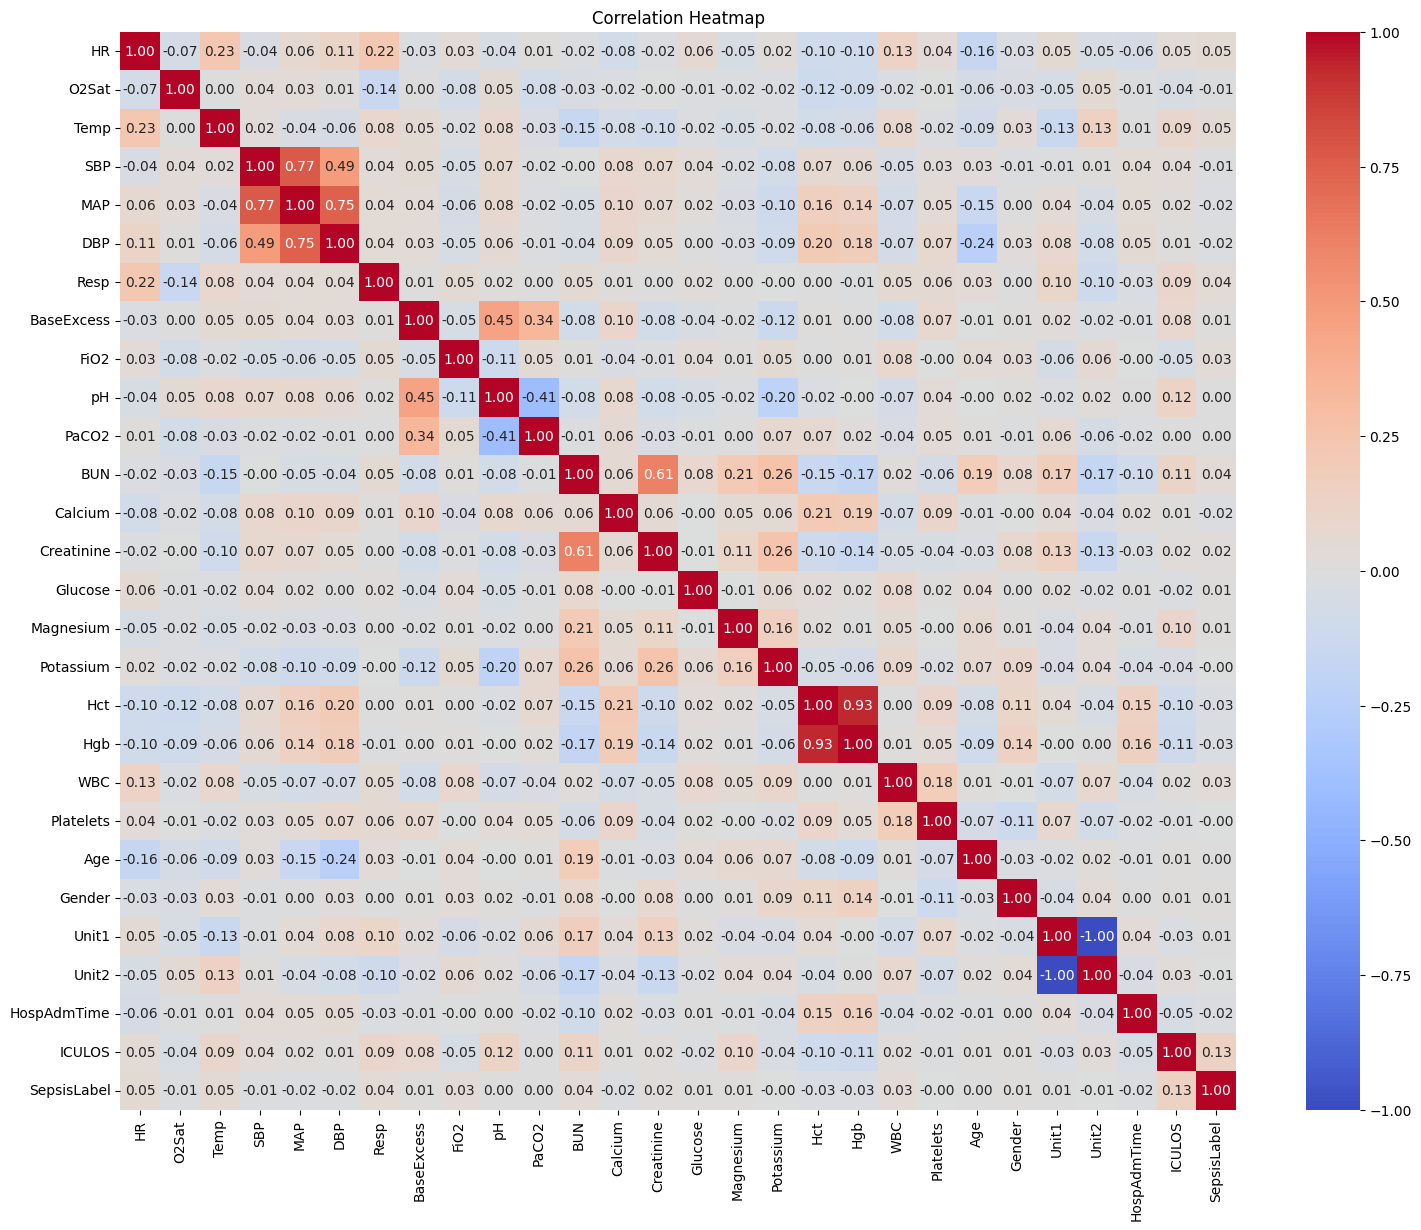

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp',
    'BaseExcess', 'FiO2', 'pH', 'PaCO2', 'BUN', 'Calcium',
    'Creatinine', 'Glucose', 'Magnesium', 'Potassium',
    'Hct', 'Hgb', 'WBC', 'Platelets', 'Age', 'Gender',
    'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS',
    'SepsisLabel'
]

plt.figure(figsize=(18, 14))

sns.heatmap(
    df[cols].corr(),
    cmap="coolwarm",
    annot=True,      # Shows correlation values
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

In [40]:
df.columns

Index(['Patient_id', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp',
       'BaseExcess', 'FiO2', 'pH', 'PaCO2', 'BUN', 'Calcium', 'Creatinine',
       'Glucose', 'Magnesium', 'Potassium', 'Hct', 'Hgb', 'WBC', 'Platelets',
       'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS',
       'SepsisLabel', 'HR_missing', 'O2Sat_missing', 'Temp_missing',
       'SBP_missing', 'MAP_missing', 'DBP_missing', 'Resp_missing',
       'BaseExcess_missing', 'FiO2_missing', 'pH_missing', 'PaCO2_missing',
       'BUN_missing', 'Calcium_missing', 'Creatinine_missing',
       'Glucose_missing', 'Magnesium_missing', 'Potassium_missing',
       'Hct_missing', 'Hgb_missing', 'WBC_missing', 'Platelets_missing',
       'Unit1_missing', 'Unit2_missing', 'HospAdmTime_missing'],
      dtype='str')